In [ ]:
# # TRABAJO PRÁCTICO: HIPÓTESIS DE TERCERIZACIÓN DEL TRABAJO DEL HOGAR (ENUT 2021)
# Exploración Estadística y Visualizaciones

# 0. CONFIGURACIÓN Y PAQUETES
# Evita notación científica en los resultados
options(scipen = 999)

# Cargar paquetes principales de Tidyverse, Janitor y Skimr
install.packages("janitor") #Si no esta instalado
install.packages("skimr")
library(tidyverse)
library(janitor)
library(skimr)

# Carpetas para guardar los resultados del TP en caso de exportar
dir.create("output/tablas", recursive = TRUE, showWarnings = FALSE)
dir.create("output/graficos", recursive = TRUE, showWarnings = FALSE)
par_original <- par(no.readonly = TRUE)



Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
# 1. CARGA, SELECCIÓN DE 10 VARIABLES Y DICCIONARIO
# ¿Las mujeres de mayor nivel educativo reducen de forma significativa sus
# minutos diarios de trabajo doméstico no remunerado propio a través de la
# tercerización mercantil paga, y cómo responde el tiempo de cuidado directo?

enut_raw <- read_delim("enut2021_base.txt", delim = "|") |>
  clean_names()
# Indicadores elegidos (código en ENUT 2021 : significado y función)

enut_sel <- enut_raw |>
  select(
    sexo_sel,
    edad_sel,
    nivel_educativo_sel,
    tcs_grupo_domestico,
    tcs_grupo_cuidado,
    cant_personashasta13,
    wper,
    dia_laborable,
    t_domestico_pago,
    condicion_actividad_agrupada
  )

#Diccionario de variables
diccionario <- tribble(
  ~variable,                      ~descripcion,                                                    ~tipo,           ~categorias_rangos,        ~funcion_estudio,
  "sexo_sel",                     "Sexo asignado al nacer",                                        "Nominal",        "1=Mujer, 2=Varón",         "Filtro: Mujeres",
  "edad_sel",                     "Edad en años cumplidos",                                        "Discreta",       "18 a 64 años",            "Filtro: Edad activa",
  "nivel_educativo_sel",          "Máximo nivel educativo alcanzado",                              "Ordinal",        "1 a 7 (4 recodificadas)", "Variable Explicativa",
  "tcs_grupo_domestico",          "Minutos diarios en trabajo doméstico no pago",                   "Continua",       "0 a 1170 min.",           "Variable Dependiente",
  "tcs_grupo_cuidado",            "Minutos diarios en cuidados directos a miembros del hogar",     "Continua",       "0 a 1860 min.",           "Variable Dependiente",
  "cant_personashasta13",         "Cantidad de niños de 0 a 13 años en el hogar",                  "Discreta",       "0 a 6 niños",             "Variable de Control",
  "wper",                         "Factor de expansión poblacional individual",                    "Discreta",       "Enteros positivos",       "Ponderador",
  "dia_laborable",                "Tipo de día relevado en el diario de actividades",             "Dicotómica",     "1=Laborable, 2=No labor.", "Variable de Control",
  "t_domestico_pago",             "Presencia de servicio doméstico pago en el hogar",              "Dicotómica",     "1=Sí, 2=No",              "Mecanismo Directo",
  "condicion_actividad_agrupada", "Inserción laboral de la persona seleccionada",                  "Nominal",        "1=Ocupada, 2=No ocupada",  "Variable de Control"
)
write_csv(diccionario, "output/tablas/diccionario_variables.csv")
diccionario

Rows: 14350 Columns: 327
── Column specification ────────────────────────────────────────────────────────
Delimiter: "|"
dbl (326): ID, WHOG, WPER, REGION, N_MIEMBRO, BHCV01, BHCV02, BHCV03, BHCV04...
lgl   (1): BHDC01_08_SEL

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


variable,descripcion,tipo,categorias_rangos,funcion_estudio
<chr>,<chr>,<chr>,<chr>,<chr>
sexo_sel,Sexo asignado al nacer,Nominal,"1=Mujer, 2=Varón",Filtro: Mujeres
edad_sel,Edad en años cumplidos,Discreta,18 a 64 años,Filtro: Edad activa
nivel_educativo_sel,Máximo nivel educativo alcanzado,Ordinal,1 a 7 (4 recodificadas),Variable Explicativa
tcs_grupo_domestico,Minutos diarios en trabajo doméstico no pago,Continua,0 a 1170 min.,Variable Dependiente
tcs_grupo_cuidado,Minutos diarios en cuidados directos a miembros del hogar,Continua,0 a 1860 min.,Variable Dependiente
cant_personashasta13,Cantidad de niños de 0 a 13 años en el hogar,Discreta,0 a 6 niños,Variable de Control
wper,Factor de expansión poblacional individual,Discreta,Enteros positivos,Ponderador
dia_laborable,Tipo de día relevado en el diario de actividades,Dicotómica,"1=Laborable, 2=No labor.",Variable de Control
t_domestico_pago,Presencia de servicio doméstico pago en el hogar,Dicotómica,"1=Sí, 2=No",Mecanismo Directo


In [ ]:
# 2. REVISIÓN GENERAL: DIMENSIONES, UNICIDAD Y TIPOS (Base inicial: N = 14.350)
# 1. Dimensiones y estructura
dim(enut_sel)
nrow(enut_sel)
ncol(enut_sel)
glimpse(enut_sel)

# 2. Comprobar unidad de observación única (sin duplicados por ID de hogar/persona)
sum(duplicated(enut_raw$id))
n_distinct(enut_raw$id) == nrow(enut_raw)

# 3. Tipos de variable reconocidos por R
tipos_iniciales <- tibble(
  variable = names(enut_sel),
   tipo_r = sapply(enut_sel, function(x) class(x)[1]))
tipos_iniciales

[1] 14350    10

[1] 14350

[1] 10

Rows: 14,350
Columns: 10
$ sexo_sel                     <dbl> 2, 1, 1, 2, 2, 1, 2, 1, 1, 2, 1, 1, 2, 2,…
$ edad_sel                     <dbl> 42, 35, 26, 43, 17, 25, 26, 42, 25, 80, 4…
$ nivel_educativo_sel          <dbl> 5, 7, 7, 5, 4, 6, 6, 7, 6, 5, 7, 6, 5, 7,…
$ tcs_grupo_domestico          <dbl> 180, 100, 240, 0, 70, 0, 20, 280, 0, 180,…
$ tcs_grupo_cuidado            <dbl> 0, 0, 0, 0, 0, 0, 0, 1740, 0, 0, 190, 510…
$ cant_personashasta13         <dbl> 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 3, 0, 0, 0,…
$ wper                         <dbl> 1580, 2175, 5078, 2182, 10202, 3960, 7956…
$ dia_laborable                <dbl> 1, 1, 2, 1, 2, 1, 2, 1, 2, 2, 1, 2, 2, 1,…
$ t_domestico_pago             <dbl> 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,…
$ condicion_actividad_agrupada <dbl> 1, 1, 1, 1, 2, 1, 2, 1, 2, 2, 1, 2, 1, 1,…


[1] 0

[1] TRUE

variable,tipo_r
<chr>,<chr>
sexo_sel,numeric
edad_sel,numeric
nivel_educativo_sel,numeric
tcs_grupo_domestico,numeric
tcs_grupo_cuidado,numeric
cant_personashasta13,numeric
wper,numeric
dia_laborable,numeric
t_domestico_pago,numeric


Revisión general: dimensiones, estructura y unicidad
La base individual reducida comprende 14.350 observaciones correspondientes a las personas seleccionadas en cada hogar y 10 variables estratégicas seleccionadas para el estudio.

Se comprueba que no existen duplicados en el identificador único (`id`), confirmando que cada fila representa de forma unívoca a un individuo encuestado mediante la Tabla de Kish en aglomerados urbanos representativos.

In [ ]:
# 3. AUDITORÍA DE VALORES FALTANTES Y CÓDIGOS DE NO RESPUESTA
# 1. Valores faltantes explícitos (NA) en la base completa
colSums(is.na(enut_sel))

# En porcentaje ordenado
faltantes_pct <- enut_sel |>
  summarise(across(everything(), ~ mean(is.na(.x)) * 100)) |>
  pivot_longer(everything(), names_to = "variable", values_to = "pct_na") |>
  arrange(desc(pct_na))
faltantes_pct

# 2. Detección de "faltantes encubiertos" (códigos del INDEC: 99 = Ns/Nc, 8 = Especial)
codigos_residuales <- tibble(
  educacion_ns_nc = sum(enut_sel$nivel_educativo_sel == 99, na.rm = TRUE),
  educacion_especial = sum(enut_sel$nivel_educativo_sel == 8, na.rm = TRUE),
  servicio_pago_ns_nc = sum(enut_sel$t_domestico_pago == 99, na.rm = TRUE)
  )
write_csv(faltantes_pct, "output/tablas/analisis_faltantes_inicial.csv")
codigos_residuales

sexo_sel                     edad_sel 
                           0                            0 
         nivel_educativo_sel          tcs_grupo_domestico 
                           0                            0 
           tcs_grupo_cuidado         cant_personashasta13 
                           0                            0 
                        wper                dia_laborable 
                           0                            0 
            t_domestico_pago condicion_actividad_agrupada 
                           0                            0

variable,pct_na
<chr>,<dbl>
sexo_sel,0
edad_sel,0
nivel_educativo_sel,0
tcs_grupo_domestico,0
tcs_grupo_cuidado,0
cant_personashasta13,0
wper,0
dia_laborable,0
t_domestico_pago,0


educacion_ns_nc,educacion_especial,servicio_pago_ns_nc
<int>,<int>,<int>
40,34,14


Completitud formal: La base presenta un 0% de valores vacíos (NA) en todas las columnas seleccionadas, producto de la estructura de carga del INDEC.

Faltantes encubiertos: Al auditar los códigos especiales de no respuesta en las 14.350 observaciones, se identifican 40 casos con código "99" (No sabe / No contesta) y 34 casos con código "8" (Educación especial) en "nivel_educativo_sel", además de 14 casos en "t_domestico_pago".

Como estos registros representan una proporción marginal del total, se justifica su exclusión directa al definir el recorte muestral objetivo sin comprometer la representatividad estadística.

In [ ]:
# 4. FILTRADO POBLACIONAL (Mujeres de 18 a 64 años con educación válida: N = 6.046)
enut_filtrada <- enut_sel |>
  filter(
    sexo_sel == 1,                             # Solo mujeres
    edad_sel >= 18 & edad_sel <= 64,           # Edad activa (18 a 64 años)
    !nivel_educativo_sel %in% c(8, 99, NA)     # Excluye Educación Especial, Ns/Nc y nulos
  )
#Filas resultantes
nrow(enut_filtrada)



[1] 6046

Al filtrar mujeres de 18 a 64 años con nivel educativo definido, se redujo la base general a 6.046 casos representativos. Esto delimita el análisis a la población femenina en edad activa y permite estudiar cómo las responsabilidades de cuidado impactan en su inserción social y laboral sin el sesgo de la etapa formativa inicial o del retiro jubilatorio.  

In [ ]:
# 5. RECODIFICACIÓN Y VARIABLES DERIVADAS

enut_clean <- enut_filtrada |>
  mutate(
  # Conversión directa a horas para evitar inconsistencias analíticas
  hs_domestico = tcs_grupo_domestico / 60,
  hs_cuidado = tcs_grupo_cuidado / 60,
    # Recodificar nivel educativo en 4 categorías
    educacion_4cat = case_when(
      nivel_educativo_sel %in% c(1, 2, 3, 4) ~ "1. Hasta Sec. Incompleto",
      nivel_educativo_sel == 5                ~ "2. Secundario Completo",
      nivel_educativo_sel == 6                ~ "3. Terciario/Univ. Incompleto",
      nivel_educativo_sel == 7                ~ "4. Terciario/Univ. Completo"
    ),

# Presencia de menores de 14 años en el hogar
     presencia_ninos = if_else(cant_personashasta13 > 0, "Con niños (0-13)", "Sin niños"),

# Tipo de dia relevado
    dia_tipo = if_else(dia_laborable == 1, "Día Laborable", "Día No Laborable"),

# Servicio doméstico remunerado en el hogar
    servicio_pago = case_when(
      t_domestico_pago == 1 ~ "Con servicio pago",
      t_domestico_pago == 2 ~ "Sin servicio pago",
      t_domestico_pago == 99 ~ NA_character_
    ),

# Condición de actividad agrupada
    estado_laboral = if_else(condicion_actividad_agrupada == 1, "Ocupada", "No ocupada")
  )
enut_clean

sexo_sel,edad_sel,nivel_educativo_sel,tcs_grupo_domestico,tcs_grupo_cuidado,cant_personashasta13,wper,dia_laborable,t_domestico_pago,condicion_actividad_agrupada,hs_domestico,hs_cuidado,educacion_4cat,presencia_ninos,dia_tipo,servicio_pago,estado_laboral
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>
1,35,7,100,0,0,2175,1,2,1,1.6666667,0.000000,4. Terciario/Univ. Completo,Sin niños,Día Laborable,Sin servicio pago,Ocupada
1,26,7,240,0,0,5078,2,1,1,4.0000000,0.000000,4. Terciario/Univ. Completo,Sin niños,Día No Laborable,Con servicio pago,Ocupada
1,25,6,0,0,0,3960,1,2,1,0.0000000,0.000000,3. Terciario/Univ. Incompleto,Sin niños,Día Laborable,Sin servicio pago,Ocupada
1,42,7,280,1740,2,2900,1,2,1,4.6666667,29.000000,4. Terciario/Univ. Completo,Con niños (0-13),Día Laborable,Sin servicio pago,Ocupada
1,25,6,0,0,0,16928,2,2,2,0.0000000,0.000000,3. Terciario/Univ. Incompleto,Sin niños,Día No Laborable,Sin servicio pago,No ocupada
1,42,7,270,190,3,6422,1,2,1,4.5000000,3.166667,4. Terciario/Univ. Completo,Con niños (0-13),Día Laborable,Sin servicio pago,Ocupada
1,20,6,360,510,0,4441,2,2,2,6.0000000,8.500000,3. Terciario/Univ. Incompleto,Sin niños,Día No Laborable,Sin servicio pago,No ocupada
1,33,7,340,0,0,3805,1,2,1,5.6666667,0.000000,4. Terciario/Univ. Completo,Sin niños,Día Laborable,Sin servicio pago,Ocupada
1,50,5,90,90,0,5245,1,2,1,1.5000000,1.500000,2. Secundario Completo,Sin niños,Día Laborable,Sin servicio pago,Ocupada


In [ ]:
# 6. RESUMEN DESCRPTIVO DE LA MUESTRA LIMPIA N = 6.046

# Dimensiones de la base con variables derivadas
dim(enut_clean)

# Estadisticas descriptivas (media, desvio, cuartiles, min y max)
tabla_skim <- enut_clean |>
select(hs_domestico, hs_cuidado, edad_sel, cant_personashasta13) |>
skim() |>
as_tibble()

write_csv(tabla_skim, "output/tablas/descriptivas_skim.csv")
tabla_skim

[1] 6046   17

skim_type,skim_variable,n_missing,complete_rate,numeric.mean,numeric.sd,numeric.p0,numeric.p25,numeric.p50,numeric.p75,numeric.p100,numeric.hist
<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
numeric,hs_domestico,0,1,3.6133256,2.7580144,0,1.5,3.166667,5.333333,19.5,▇▅▁▁▁
numeric,hs_cuidado,0,1,2.3717334,4.2743446,0,0.0,0.000000,3.000000,31.0,▇▁▁▁▁
numeric,edad_sel,0,1,40.2892822,13.2800655,18,29.0,39.000000,52.000000,64.0,▇▇▇▆▇
numeric,cant_personashasta13,0,1,0.7074099,0.9774469,0,0.0,0.000000,1.000000,6.0,▇▂▁▁▁


Dedicación al trabajo doméstico "hs_domestico" :
Las mujeres activas destinan en promedio 3,61 horas diarias a tareas del hogar, con una mediana de 3,17 horas y un rango intercuartílico de 1,50 a 5,33 horas.
La asimetría hacia la derecha se evidencia en la presencia de colas largas con registros que alcanzan hasta 19,5 horas.

Tareas de cuidado "hs_cuidado":
Presenta una mediana de 0 horas, ausencia de menores o dependientes en parte de los hogares, una media de 2,37 horas y un percentil 75 de 3 horas diarias.

Perfil etario y carga familiar:
La edad media se sitúa en 40,29 años y el promedio de niños menores de 14 años es de 0,71 por hogar.

In [ ]:
# 7. FRECUENCIAS SIMPLES Y TABLA CRUZADA DE TERCERIZACIÓN
# 1. Frecuencias simples del nivel educativo (absolutas y porcentuales)
freq_educ <- table(enut_clean$educacion_4cat)
prop_educ <- round(prop.table(freq_educ) * 100, 1)

# 2. Tabla cruzada: Nivel educativo vs. Servicio doméstico pago
tabla_cruzada_tercerizacion <- table(enut_clean$educacion_4cat,
enut_clean$servicio_pago)
addmargins(tabla_cruzada_tercerizacion)

# 3. Proporciones por fila (% horizontal dentro de cada nivel educativo)
prop_tercerizacion_fila <- round(prop.table(tabla_cruzada_tercerizacion, margin = 1) * 100, 1)

# Exportar las tablas a la carpeta output
write.csv(as.data.frame(tabla_cruzada_tercerizacion),
 "output/tablas/tabla_cruzada_tercerizacion_conteo.csv", row.names = FALSE)
 write.csv(as.data.frame.matrix(prop_tercerizacion_fila),
 "output/tablas/tabla_cruzada_tercerizacion_pct.csv")

prop_tercerizacion_fila

,Con servicio pago,Sin servicio pago,Sum
1. Hasta Sec. Incompleto,20,1641,1661
2. Secundario Completo,46,1632,1678
3. Terciario/Univ. Incompleto,57,1135,1192
4. Terciario/Univ. Completo,222,1289,1511
Sum,345,5697,6042


                               
                                Con servicio pago Sin servicio pago
  1. Hasta Sec. Incompleto                    1.2              98.8
  2. Secundario Completo                      2.7              97.3
  3. Terciario/Univ. Incompleto               4.8              95.2
  4. Terciario/Univ. Completo                14.7              85.3

In [ ]:
# 8. TABLAS PONDERADAS CON FACTOR DE EXPANSIÓN (WPER)
# TABLA 1: Tiempo de trabajo en el hogar y tercerización por nivel educativo
tabla_1_educacion <- enut_clean |>
  group_by(educacion_4cat) |>
  summarise(
  casos_muestra = n(),
  poblacion_expandida = sum(wper),
  hs_domestico_prom = round(weighted.mean(hs_domestico, w = wper), 2),
  hs_cuidado_prom = round(weighted.mean(hs_cuidado, w = wper), 2),
  pct_servicio_pago = round((sum(wper[servicio_pago == "Con servicio pago"], na.rm = TRUE) / sum(wper)) * 100, 1),
  .groups = "drop"
  )
write_csv(tabla_1_educacion, "output/tablas/tabla_1_educacion_tercerizacion.csv")
print("=== TABLA 1: TRABAJO DEL HOGAR Y TERCERIZACION ===")
tabla_1_educacion

# TABLA 2: Control por tipo de día (Laborable vs. No Laborable)
tabla_2_dias <- enut_clean |>
group_by(educacion_4cat, dia_tipo) |>
summarise(
hs_domestico_prom = round(weighted.mean(hs_domestico, w = wper), 2),
hs_cuidado_prom = round(weighted.mean(hs_cuidado, w = wper), 2),
.groups = "drop"
)
write_csv(tabla_2_dias, "output/tablas/tabla_2_control_dias.csv")
print("=== TABLA 2: CONTROL POR TIPO DE DÍA ===")
tabla_2_dias

# TABLA 3: Mujeres ocupadas y presencia de menores (Carga familiar)
tabla_3_ocupadas <- enut_clean |>
filter(estado_laboral == "Ocupada") |>
group_by(educacion_4cat, presencia_ninos) |>
summarise(
hs_domestico_prom = round(weighted.mean(hs_domestico, w = wper), 2),
hs_cuidado_prom = round(weighted.mean(hs_cuidado, w = wper), 2),
.groups = "drop"
)
write_csv(tabla_3_ocupadas, "output/tablas/tabla_3_mujeres_ocupadas_ninos.csv")
print("=== TABLA 3: OCUPADAS Y MENORES DE 14 ===")
tabla_3_ocupadas


[1] "=== TABLA 1: TRABAJO DEL HOGAR Y TERCERIZACION ==="


educacion_4cat,casos_muestra,poblacion_expandida,hs_domestico_prom,hs_cuidado_prom,pct_servicio_pago
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
1. Hasta Sec. Incompleto,1663,2692109,4.65,2.85,1.2
2. Secundario Completo,1679,2480132,3.81,2.51,3.0
3. Terciario/Univ. Incompleto,1193,1913169,2.71,1.84,5.4
4. Terciario/Univ. Completo,1511,2114977,3.30,1.95,17.0


[1] "=== TABLA 2: CONTROL POR TIPO DE DÍA ==="


educacion_4cat,dia_tipo,hs_domestico_prom,hs_cuidado_prom
<chr>,<chr>,<dbl>,<dbl>
1. Hasta Sec. Incompleto,Día Laborable,3.34,1.92
1. Hasta Sec. Incompleto,Día No Laborable,5.30,3.31
2. Secundario Completo,Día Laborable,2.83,1.55
2. Secundario Completo,Día No Laborable,4.79,3.46
3. Terciario/Univ. Incompleto,Día Laborable,2.29,1.43
3. Terciario/Univ. Incompleto,Día No Laborable,3.01,2.13
4. Terciario/Univ. Completo,Día Laborable,2.41,1.59
4. Terciario/Univ. Completo,Día No Laborable,4.59,2.47


[1] "=== TABLA 3: OCUPADAS Y MENORES DE 14 ==="


educacion_4cat,presencia_ninos,hs_domestico_prom,hs_cuidado_prom
<chr>,<chr>,<dbl>,<dbl>
1. Hasta Sec. Incompleto,Con niños (0-13),3.77,4.19
1. Hasta Sec. Incompleto,Sin niños,3.75,0.32
2. Secundario Completo,Con niños (0-13),3.39,3.83
2. Secundario Completo,Sin niños,2.97,0.32
3. Terciario/Univ. Incompleto,Con niños (0-13),3.29,4.25
3. Terciario/Univ. Incompleto,Sin niños,2.07,0.21
4. Terciario/Univ. Completo,Con niños (0-13),3.33,5.11
4. Terciario/Univ. Completo,Sin niños,2.58,0.17


Efecto sustitución en tareas del hogar (Tabla 1):La tasa de tercerización formal del trabajo doméstico escala progresivamente con el nivel educativo: apenas el 1,2% en mujeres con hasta secundario incompleto, 3,0% en secundario completo, 5,4% en nivel superior incompleto y un salto al 17,0% en graduadas universitarias.

Como contrapartida directa, la carga diaria promedio de trabajo doméstico no remunerado se reduce de 4,65 a 3,30 horas diarias, confirmando la delegación efectiva de tareas operativas.

Elasticidad semanal del trabajo no remunerado (Tabla 2):Al controlar por tipo de jornada, los días no laborables concentran una intensificación del trabajo doméstico en todos los estratos (promediando entre 4,6 y 5,3 horas).

Cuidado no delegable en mujeres ocupadas (Tabla 3):Entre las mujeres activas en el mercado de trabajo, la presencia de menores de 14 años demanda entre 3,8 y 5,1 horas de cuidado diario, sin que el nivel de instrucción lo reduzca.

Diagnóstico de consistencia y completitud
La base final depurada (`enut_clean`) reúne 6.046 observaciones y 15 variables (10 originales y 5 derivadas). La exploración confirma la ausencia de registros duplicados por identificador de hogar y una completitud del 100% (sin valores faltantes ni `NA`) en todas las dimensiones seleccionadas para el estudio.

In [ ]:
# 9. CRUCES ADICIONALES (devolución de la 1ª instancia)
# Pegar como celda nueva DESPUÉS de la sección 8 del notebook.
# Requiere: enut_clean (sección 5), con las variables ya creadas:
#   hs_domestico, hs_cuidado, wper, educacion_4cat, estado_laboral,
#   presencia_ninos, dia_tipo, servicio_pago, cant_personashasta13, edad_sel
# Todos los promedios son PONDERADOS con wper (igual que la 1ª entrega);
# n y % de la muestra son casos sin ponderar.

# --- Variable auxiliar: niños en 3 categorías --------------------------------
enut_clean <- enut_clean |>
  mutate(
    ninos_cat = case_when(
      cant_personashasta13 == 0 ~ "Sin niños",
      cant_personashasta13 == 1 ~ "1 niño/a",
      TRUE                      ~ "2 o más niños"
    )
  )
# --- Función: promedios de horas por grupo -----------------------------------
cruce_horas <- function(data, variable, etiqueta) {
  data |>
    filter(!is.na({{ variable }})) |>          # saca los 4 Ns/nc de servicio pago
    group_by(grupo = {{ variable }}) |>
    summarise(
      n = n(),
      hs_domestico_prom = round(weighted.mean(hs_domestico, w = wper), 2),
      hs_cuidado_prom   = round(weighted.mean(hs_cuidado,   w = wper), 2),
      .groups = "drop"
    ) |>
    mutate(
      variable    = etiqueta,
      pct_muestra = round(100 * n / sum(n), 1)
    ) |>
    select(variable, grupo, n, pct_muestra, hs_domestico_prom, hs_cuidado_prom)
}
# --- TABLA A: horas según otras variables (no solo educación) ----------------
tabla_cruces <- bind_rows(
  cruce_horas(enut_clean, servicio_pago,  "Servicio doméstico pago"),
  cruce_horas(enut_clean, estado_laboral, "Condición de actividad"),
  cruce_horas(enut_clean, ninos_cat,      "Niños 0-13 en el hogar"),
  cruce_horas(enut_clean, dia_tipo,       "Tipo de día")
)
write_csv(tabla_cruces, "output/tablas/tabla_cruces_adicionales.csv")
print("=== TABLA A: CRUCES ADICIONALES (promedios ponderados) ===")
tabla_cruces

# --- TABLA B: perfil de cada nivel educativo (ponderado) ---------------------
# Sirve para explicar por qué educación y horas NO se relacionan en línea recta
perfil_educ <- enut_clean |>
  group_by(educacion_4cat) |>
  summarise(
    n = n(),
    edad_media        = round(weighted.mean(edad_sel, w = wper), 1),
    pct_ocupadas      = round(100 * weighted.mean(estado_laboral == "Ocupada", w = wper), 1),
    pct_con_ninos     = round(100 * weighted.mean(presencia_ninos == "Con niños (0-13)", w = wper), 1),
    pct_servicio_pago = round(100 * weighted.mean(servicio_pago == "Con servicio pago",
                                                  w = wper, na.rm = TRUE), 1),
    .groups = "drop"
  )
write_csv(perfil_educ, "output/tablas/perfil_por_nivel_educativo.csv")
print("=== TABLA B: PERFIL POR NIVEL EDUCATIVO (ponderado) ===")
perfil_educ


[1] "=== TABLA A: CRUCES ADICIONALES (promedios ponderados) ==="


variable,grupo,n,pct_muestra,hs_domestico_prom,hs_cuidado_prom
<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
Servicio doméstico pago,Con servicio pago,345,5.7,2.71,2.05
Servicio doméstico pago,Sin servicio pago,5697,94.3,3.77,2.36
Condición de actividad,No ocupada,2073,34.3,4.82,3.17
Condición de actividad,Ocupada,3973,65.7,3.06,1.85
Niños 0-13 en el hogar,1 niño/a,1392,23.0,3.96,4.20
Niños 0-13 en el hogar,2 o más niños,1216,20.1,4.45,6.23
Niños 0-13 en el hogar,Sin niños,3438,56.9,3.36,0.27
Tipo de día,Día Laborable,2872,47.5,2.71,1.62
Tipo de día,Día No Laborable,3174,52.5,4.55,2.94


[1] "=== TABLA B: PERFIL POR NIVEL EDUCATIVO (ponderado) ==="


educacion_4cat,n,edad_media,pct_ocupadas,pct_con_ninos,pct_servicio_pago
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
1. Hasta Sec. Incompleto,1663,42.3,47.4,49.5,1.2
2. Secundario Completo,1679,39.1,65.5,48.7,3.0
3. Terciario/Univ. Incompleto,1193,30.8,60.6,36.4,5.4
4. Terciario/Univ. Completo,1511,43.7,82.3,32.4,17.0


agg_record_84215af691f 
                     2

agg_record_84215af691f 
                     2

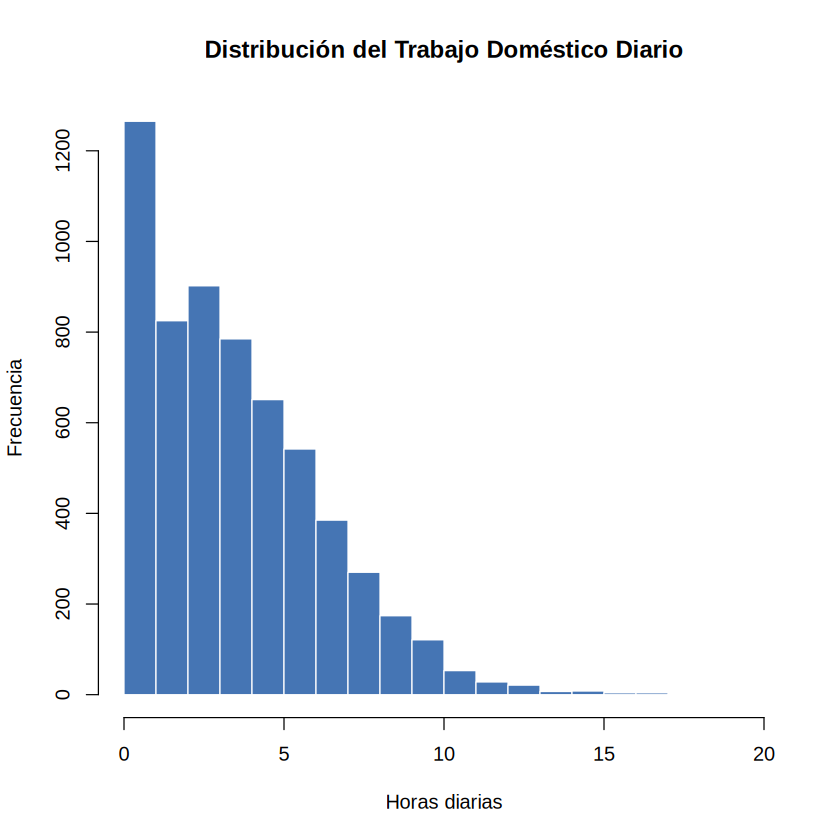

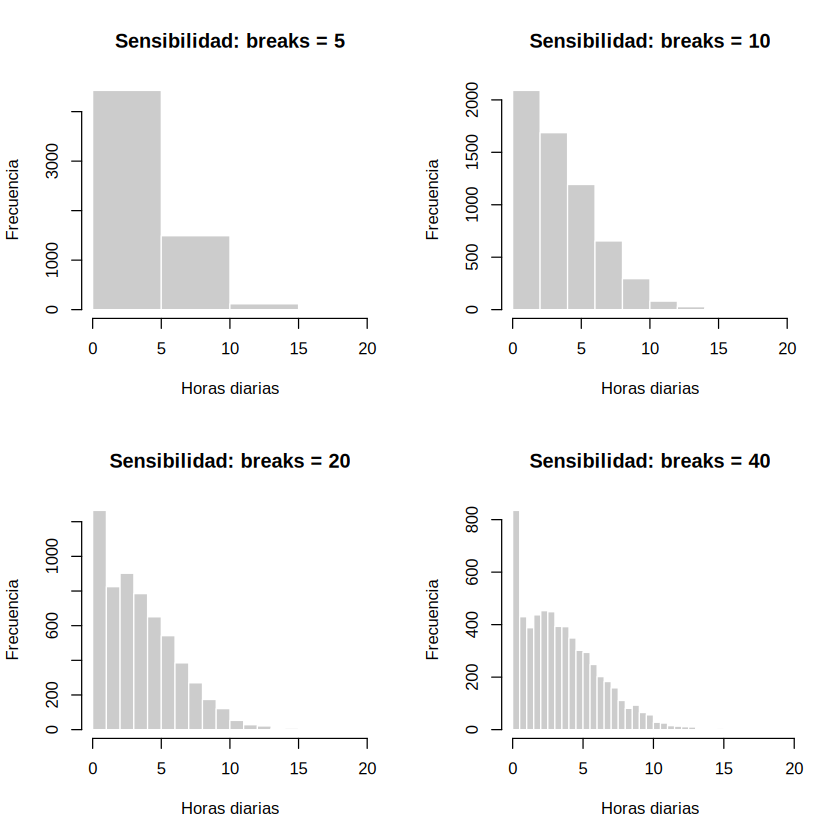

In [ ]:
# 10. HISTOGRAMAS

# 1. HISTOGRAMA GENERAL
# Guardar
png("output/graficos/histograma_trabajo_domestico.png", width = 800, height =
600, res = 120)
hist(enut_clean$hs_domestico,
breaks = 20,
col = "#4575b4",
border = "white",
main = "Distribución del Trabajo Doméstico Diario",
xlab = "Horas diarias",
ylab = "Frecuencia")
dev.off()

# Mostrar en pantalla
hist(enut_clean$hs_domestico,
breaks = 20,
col = "#4575b4",
border = "white",
main = "Distribución del Trabajo Doméstico Diario",
xlab = "Horas diarias",
ylab = "Frecuencia")

# 2. PANEL COMPARATIVO DE SENSIBILIDAD
# Guardar
png("output/graficos/histograma_sensibilidad.png", width = 800, height = 600,
res = 120)
par(mfrow = c(2, 2))
for (b in c(5, 10, 20, 40)) {
  hist(enut_clean$hs_domestico,
  breaks = b,
  main = paste("Sensibilidad: breaks =", b),
  xlab = "Horas diarias",
  ylab = "Frecuencia",
  col = "grey80",
  border = "white")
  }
  dev.off()

# Mostrar en pantalla
par(mfrow = c(2, 2))
for (b in c(5, 10, 20, 40)) {
  hist(enut_clean$hs_domestico,
  breaks = b,
  main = paste("Sensibilidad: breaks =", b),
  xlab = "Horas diarias",
  ylab = "Frecuencia",
  col = "grey80",
  border = "white")
  }
  par(mfrow = c(1, 1))


Forma y distribución: La dedicación al trabajo doméstico presenta una marcada asimetría hacia la derecha, con la mayor concentración de mujeres entre 1 y 4 horas diarias y una cola larga que llega hasta casi 20 horas.

agg_record_84242833773 
                     2

[1] "=== CINCO NÚMEROS DEL BOXPLOT (HORAS) ==="


[1]  0.00  1.50  3.17  5.33 11.00

[1] "=== TOTAL DE VALORES ATÍPICOS IDENTIFICADOS ==="


[1] 73

[1] "=== PRIMEROS 15 VALORES ATÍPICOS (HORAS) ==="


[1] 11.17 11.17 11.17 11.17 11.17 11.33 11.33 11.33 11.33 11.33 11.50 11.50
[13] 11.50 11.50 11.50

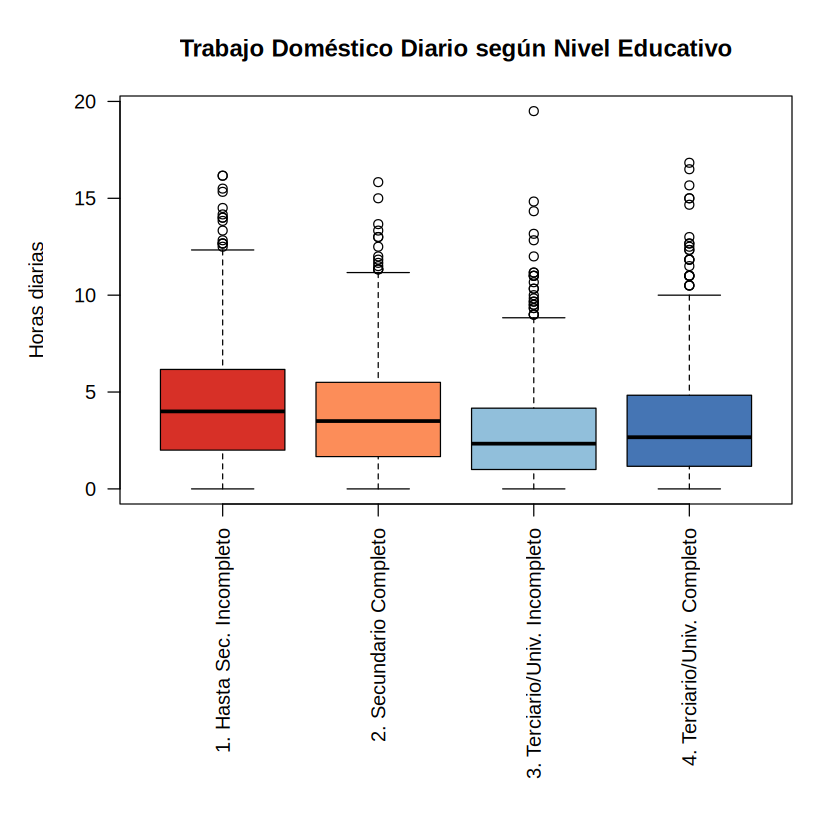

In [ ]:
# 11. DIAGRAMA DE CAJA (BOXPLOT) Y DETECCIÓN DE VALORES ATÍPICOS
# Guardar gráfico en disco
png("output/graficos/boxplot_domestico_educacion.png", width =
  800, height = 600)
  par(mar = c(14, 5, 4, 2))
  boxplot(hs_domestico ~ educacion_4cat,
  data = enut_clean,
  main = "Trabajo Doméstico Diario según Nivel Educativo",
  xlab = "",
  ylab = "Horas diarias",
  col = c("#d73027", "#fc8d59", "#91bfdb", "#4575b4"),
  las = 2)
dev.off()

# Mostrar en pantalla
par(mar = c(14, 5, 4, 2))
boxplot(hs_domestico ~ educacion_4cat,
data = enut_clean,
main = "Trabajo Doméstico Diario según Nivel Educativo",
xlab = "",
ylab = "Horas diarias",
col = c("#d73027", "#fc8d59", "#91bfdb", "#4575b4"),
las = 2)
par(mar = c(14, 5, 4, 2))

# Inspección técnica de outliers sobre la variable en horas
bp_stats <- boxplot.stats(enut_clean$hs_domestico)
print("=== CINCO NÚMEROS DEL BOXPLOT (HORAS) ===")
round(bp_stats$stats, 2)

print("=== TOTAL DE VALORES ATÍPICOS IDENTIFICADOS ===")
length(bp_stats$out)

print("=== PRIMEROS 15 VALORES ATÍPICOS (HORAS) ===")
head(round(sort(bp_stats$out), 2), 15)


Comportamiento por nivel educativo:
La mediana y la dispersión descienden a medida que aumenta el nivel de instrucción: las mujeres con hasta secundario incompleto registran la mayor carga y variabilidad, mientras que en los niveles superiores las cajas se ubican más abajo y son más homogéneas, reflejando una menor dedicación horaria directa.

Detección de atípicos: El umbral estadístico se sitúa en 11 horas diarias, identificando 73 casos que superan ese valor (con máximos de 19,5 horas) Jornadas reales de sobrecarga extrema de tareas no remuneradas en el hogar.

In [ ]:
# 12. PERCENTILES, RATIOS DE DESIGUALDAD Y CORRELACIONES
# 1. Ratios de desigualdad en horas de trabajo doméstico
ratios_tabla <- tibble(
p10 = quantile(enut_clean$hs_domestico, 0.10),
p25 = quantile(enut_clean$hs_domestico, 0.25),
p50 = quantile(enut_clean$hs_domestico, 0.50),
p75 = quantile(enut_clean$hs_domestico, 0.75),
p90 = quantile(enut_clean$hs_domestico, 0.90),
ratio_90_10 = round(p90 / ifelse(p10 == 0, 0.1, p10), 2),
ratio_75_25 = round(p75 / ifelse(p25 == 0, 0.1, p25), 2)
)
write_csv(ratios_tabla, "output/tablas/ratios_percentiles.csv")
print("=== RATIOS DE DESIGUALDAD (HS_DOMESTICO) ===")
ratios_tabla


# 2. Matriz y ranking de correlaciones bivariadas
vars_num <- enut_clean |>
select(hs_domestico, hs_cuidado, edad_sel, cant_personashasta13)

vars_num <- enut_clean |> select(hs_domestico, hs_cuidado, edad_sel,
cant_personashasta13)

mat_cor <- cor(vars_num, use = "pairwise.complete.obs")

cor_ranking <- as.data.frame(as.table(mat_cor)) |>
  as_tibble() |>
  rename(var1 = Var1, var2 = Var2, r = Freq) |>
  filter(var1 != var2) |>
  mutate(par = map2_chr(as.character(var1), as.character(var2), ~
  paste(sort(c(.x, .y)), collapse = " - "))) |>
  distinct(par, .keep_all = TRUE) |>
  arrange(desc(abs(r))) |>
  mutate(r = round(r, 2)) |>
  select(par, r)

 write_csv(cor_ranking, "output/tablas/correlaciones_ranking.csv")
 print("=== RANKING DE CORRELACIONES BIVARIADAS ===")
 cor_ranking

[1] "=== RATIOS DE DESIGUALDAD (HS_DOMESTICO) ==="


p10,p25,p50,p75,p90,ratio_90_10,ratio_75_25
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0.3333333,1.5,3.166667,5.333333,7.333333,22,3.56


[1] "=== RANKING DE CORRELACIONES BIVARIADAS ==="


par,r
<chr>,<dbl>
cant_personashasta13 - hs_cuidado,0.55
cant_personashasta13 - edad_sel,-0.27
edad_sel - hs_domestico,0.21
edad_sel - hs_cuidado,-0.19
hs_cuidado - hs_domestico,0.18
cant_personashasta13 - hs_domestico,0.15


La estructura horaria de "hs_domestico" presenta una marcada heterogeneidad. Mientras que el primer decil apenas reporta 20 minutos diarios (p10 = 0,33 hs), el decil superior supera las 7 horas diarias (p90 = 7,33 hs). El ratio intercuartílico (P75/P25 = 3,56) refleja que el tramo alto triplica la jornada del tramo bajo, brecha que escala a un ratio P90/P10 de 22,0 veces al comparar los extremos de la distribución.

La relación bivariada de mayor magnitud corresponde a la presencia de menores de 14 años sobre las horas de cuidado directo (r = 0,55)

La correlación entre trabajo doméstico y cuidado directo resulta reducida (r = 0,18). Esto valida la decisión analítica de descomponer el trabajo no remunerado en dos vectores independientes, ya que la tercerización actúa sobre las tareas materiales del hogar y no sobre la labor parental de cuidado.

agg_record_8422df21741 
                     2

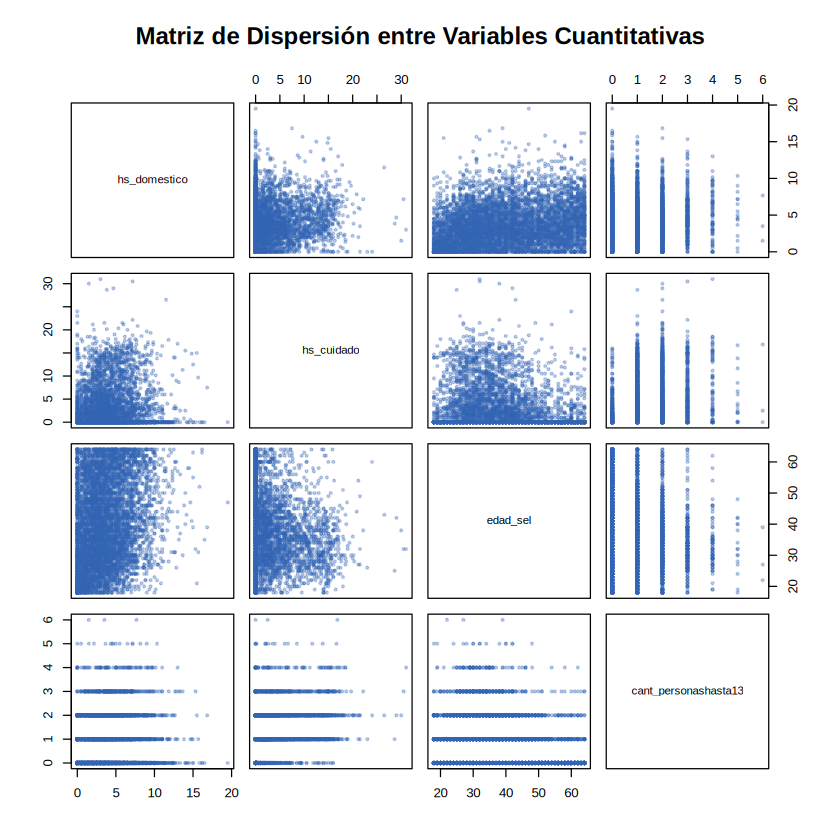

In [ ]:
# 13. MATRIZ DE DISPERSIÓN GRÁFICA

# Seleccionar variables cuantitativas en horas
vars_dispersion <- enut_clean |>
  select(hs_domestico, hs_cuidado, edad_sel,
  cant_personashasta13)


# 1. Guardar gráfico de pares en disco
png("output/graficos/matriz_dispersion_pairs.png", width = 800,
height = 800)
pairs(vars_dispersion,
      pch = 19,
      cex = 0.5,
      col = rgb(0.2, 0.4, 0.7, 0.3),
      main = "Matriz de Dispersión entre Variables Cuantitativas")
 dev.off()

# Mostrar grafico
pairs(vars_dispersion,
   pch = 19,
   cex = 0.5,
   col = rgb(0.2, 0.4, 0.7, 0.3),
   main = "Matriz de Dispersión entre Variables Cuantitativas")

# 3. Exportar base de datos depurada final
write_csv(enut_clean, "output/tablas/enut_muestra_6046_clean.csv")


Concentración en origen y asimetría conjunta ("hs_domestico" vs. "hs_cuidado"): La nube de puntos se agrupa de forma densa en la esquina inferior izquierda (valores bajos de ambas variables), con una dispersión que se atenúa hacia los extremos

Estructura escalonada con menores a cargo ("cant_personashasta13" vs. "hs_cuidado"):En los cruces con la cantidad de niños se observan franjas o líneas horizontales y verticales paralelas debido a la naturaleza discreta de la variable

Dispersión homogénea por edad ("edad_sel"):La relación entre la edad y las horas de trabajo no remunerado muestra nubes de puntos extendidas de manera uniforme a lo largo del eje horizontal de 18 a 64 años, sin concentración en curvas pronunciadas

In [ ]:
system("zip -r entrega_graficos_tp1.zip output")

In [ ]:
# 14. Parte Pilar: missing values y outliers

# cargado de base de datos
# sep = "|" porque los datos están separados por barras
datos <- read.delim("enut2021_base.txt", sep = "|", header = TRUE, dec = ".")

# dimensiones iniciales de toda la base
print("Dimensiones totales de la base:")
print(dim(datos))

# filtro de la muestra del estudio:
# Mujeres (SEXO_SEL == 1) con edad entre 18 y 64 años (EDAD_SEL)
datos_muestra <- subset(datos, SEXO_SEL == 1 & EDAD_SEL >= 18 & EDAD_SEL <= 64)

# tamaño de muestra depurada (debe rondar los 6.077 casos)
print("Tamaño de la muestra filtrada (Mujeres 18-64 años):")
print(nrow(datos_muestra))

# valores faltantes (exclusión de Ns/nc y educación especial)
# Se descartan códigos no aplicables/sin dato en educación y servicio doméstico
datos_muestra <- subset(
  datos,
  SEXO_SEL == 1 &
  EDAD_SEL >= 18 &
  EDAD_SEL <= 64 &
  !(NIVEL_EDUCATIVO_SEL %in% c(8, 9, 99)) &
  !(T_DOMESTICO_PAGO %in% c(9, 99))
)

# tamaño final de la muestra depurada
print(paste("Tamaño de la muestra final depurada:", nrow(datos_muestra)))

# variables clave del estudio
variables_interes <- c(
  "SEXO_SEL", "EDAD_SEL", "NIVEL_EDUCATIVO_SEL",
  "TCS_GRUPO_DOMESTICO", "TCS_GRUPO_CUIDADO",
  "CANT_PERSONASHASTA13", "WPER", "DIA_LABORABLE",
  "T_DOMESTICO_PAGO", "CONDICION_ACTIVIDAD_AGRUPADA"
)

# missing Values en las variables seleccionadas (sobre la muestra depurada)
valores_perdidos <- colSums(is.na(datos_muestra[, variables_interes]))
print("Cantidad de missing values por variable en la muestra depurada:")
print(valores_perdidos)

# corroboración de que no queden missing values en nuestras variables principales:)

# cálculo de IQR y Outliers en Trabajo Doméstico
q1 <- quantile(datos_muestra$TCS_GRUPO_DOMESTICO, 0.25)
q3 <- quantile(datos_muestra$TCS_GRUPO_DOMESTICO, 0.75)
iqr_val <- IQR(datos_muestra$TCS_GRUPO_DOMESTICO)

limite_sup <- q3 + (1.5 * iqr_val)

# identificación de outliers
outliers <- datos_muestra$TCS_GRUPO_DOMESTICO[datos_muestra$TCS_GRUPO_DOMESTICO > limite_sup]

# resultados en pantalla
print(paste("Q1 (25%):", q1))
print(paste("Q3 (75%):", q3))
print(paste("IQR:", iqr_val))
print(paste("Límite superior para atípicos:", limite_sup))
print(paste("Cantidad de outliers detectados:", length(outliers)))


[1] "Dimensiones totales de la base:"
[1] 14350   327
[1] "Tamaño de la muestra filtrada (Mujeres 18-64 años):"
[1] 6077
[1] "Tamaño de la muestra final depurada: 6042"
[1] "Cantidad de missing values por variable en la muestra depurada:"
                    SEXO_SEL                     EDAD_SEL 
                           0                            0 
         NIVEL_EDUCATIVO_SEL          TCS_GRUPO_DOMESTICO 
                           0                            0 
           TCS_GRUPO_CUIDADO         CANT_PERSONASHASTA13 
                           0                            0 
                        WPER                DIA_LABORABLE 
                           0                            0 
            T_DOMESTICO_PAGO CONDICION_ACTIVIDAD_AGRUPADA 
                           0                            0 
[1] "Q1 (25%): 90"
[1] "Q3 (75%): 320"
[1] "IQR: 230"
[1] "Límite superior para atípicos: 665"
[1] "Cantidad de outliers detectados: 73"


In [ ]:
# ==============================================================================
# INFERENCIA ESTADÍSTICA Y REGRESIÓN MULTIVARIADA
# ==============================================================================

# 0. CARGA DE PAQUETES Y CONFIGURACIÓN DEL ENTORNO DE TRABAJO

# 0.1. Instalación rápida de paquetes a nivel sistema operativo en Colab
system("apt-get update -qq")
system("apt-get install -y --no-install-recommends r-cran-sandwich r-cran-car r-cran-lmtest r-cran-modelsummary")

# 0.2. Carga de librerías para inferencia y regresión
library(car)
library(modelsummary)
library(sandwich)
library(lmtest)
library(ggplot2)

# 0.3. Verificación de continuidad: confirmación de la muestra limpia
cat("Muestra recibida para inferencia:", nrow(enut_clean), "observaciones.\n")

# 0.4. Estética para gráficos de ggplot2
theme_set(theme_minimal(base_size = 12))

Muestra recibida para inferencia: 6046 observaciones.


**apt-get** (Instalación en Colab): Se utiliza el gestor de paquetes de Linux para instalar las dependencias C++ de R en Google Colab de forma rápida y sin errores de compilación.


---


**Paquetes:**




**car**: Permite calcular el VIF para diagnosticar la multicolinealidad.

**sandwich y lmtest**: Para estimar el modelo MCO con errores estándar robustos frente a la heterocedasticidad.

**modelsummary:** Se utiliza para generar el gráfico de coeficientes e intervalos de confianza (modelplot).

In [ ]:
# 1. RECODIFICACIÓN A FACTORES Y DEFINICIÓN DE GRUPOS BASE PARA LA REGRESIÓN
enut_reg <- enut_clean %>%
  mutate(
  educacion_4cat = factor(educacion_4cat, levels = c(
      "1. Hasta Sec. Incompleto",
      "2. Secundario Completo",
      "3. Terciario/Univ. Incompleto",
      "4. Terciario/Univ. Completo"
    )),
  servicio_pago   = factor(servicio_pago, levels = c("Sin servicio pago", "Con servicio pago")),
  presencia_ninos = factor(presencia_ninos, levels = c("Sin niños", "Con niños (0-13)")),
  dia_tipo        = factor(dia_tipo),
  estado_laboral  = factor(estado_laboral)
  )

# Verificación de los niveles asignados
levels(enut_reg$educacion_4cat)

[1] "1. Hasta Sec. Incompleto"      "2. Secundario Completo"       
[3] "3. Terciario/Univ. Incompleto" "4. Terciario/Univ. Completo"

Se recodifican las variables categóricas (`educacion_4cat`, `servicio_pago`, `presencia_ninos`, `estado_laboral` y `dia_tipo`) a tipo `factor` para incorporarlas como **variables explicativas y de control** en la regresión lineal multivariada MCO.

Se elige como base los grupos de control o situaciones estándar (piso educativo, sin servicio pago, sin niños, no ocupada y dia laborable) para que todos los coeficientes de la regresión muestren directamente el impacto o cambio en horas al salir de esa situación base.

In [ ]:
# 2. ANÁLISIS DE CORRELACIÓN DE PEARSON (VARIABLES CUANTITATIVAS)

# 2.1. Selección de variables cuantitativas continuas
vars_num <- enut_reg |>
  select(hs_domestico, hs_cuidado, edad_sel, cant_personashasta13)

# 2.2. Matriz de correlaciones de Pearson
mat_cor <- cor(vars_num, use = "pairwise.complete.obs")

cat("=== MATRIZ DE CORRELACIONES DE PEARSON ===\n")
print(round(mat_cor, 2))

# ==============================================================================
# ANÁLISIS DE CORRELACIÓN DE PEARSON (VARIABLES CUANTITATIVAS)
# ==============================================================================

# 1. Selección de variables cuantitativas continuas
vars_num <- enut_reg |>
  select(hs_domestico, hs_cuidado, edad_sel, cant_personashasta13)

# 2. Matriz de correlaciones de Pearson
mat_cor <- cor(vars_num, use = "pairwise.complete.obs")

cat("=== MATRIZ DE CORRELACIONES DE PEARSON ===\n")
print(round(mat_cor, 2))

# 3. Ranking ordenado de pares (Tidy format - Cátedra)
cor_ranking <- as.data.frame(as.table(mat_cor)) |>
  as_tibble() |>
  rename(var1 = Var1, var2 = Var2, r = Freq) |>
  filter(var1 != var2) |>
  mutate(par = map2_chr(as.character(var1), as.character(var2),
                        ~ paste(sort(c(.x, .y)), collapse = " - "))) |>
  distinct(par, .keep_all = TRUE) |>
  arrange(desc(abs(r))) |>
  mutate(r = round(r, 2)) |>
  select(par, r)

cat("\n=== RANKING DE CORRELACIONES ===\n")
print(cor_ranking)
write_csv(as.data.frame(mat_cor), "output/tablas/matriz_correlaciones.csv")
write_csv(cor_ranking, "output/tablas/ranking_correlaciones.csv")

=== MATRIZ DE CORRELACIONES DE PEARSON ===
                     hs_domestico hs_cuidado edad_sel cant_personashasta13
hs_domestico                 1.00       0.18     0.21                 0.15
hs_cuidado                   0.18       1.00    -0.19                 0.55
edad_sel                     0.21      -0.19     1.00                -0.27
cant_personashasta13         0.15       0.55    -0.27                 1.00
=== MATRIZ DE CORRELACIONES DE PEARSON ===
                     hs_domestico hs_cuidado edad_sel cant_personashasta13
hs_domestico                 1.00       0.18     0.21                 0.15
hs_cuidado                   0.18       1.00    -0.19                 0.55
edad_sel                     0.21      -0.19     1.00                -0.27
cant_personashasta13         0.15       0.55    -0.27                 1.00

=== RANKING DE CORRELACIONES ===
# A tibble: 6 × 2
  par                                     r
  <chr>                               <dbl>
1 cant_personashasta13 -

Se realiza un análisis de correlaciones entre las variables cuantitativas continuas necesario para diagnosticar la dirección e intensidad de la asociación lineal entre las covariables numéricas y descarrtar problemas de multicolinealidad antes de la estimación del modelo de regresión MCO.

In [ ]:
# 3. TEST DE ANOVA: hs_domestico ~ educacion_4cat
# Pregunta: ¿Las diferencias medias de tiempo doméstico según educación son significativas?
# H0: mu_inicial = mu_secundario = mu_terciario = mu_universitario
# H1: Al menos un nivel educativo tiene una media de horas diferente

cat("=========================================================\n")
cat("1. TEST DE ANOVA (Dedicación doméstica vs Educación)\n")
cat("=========================================================\n")

# 3.1. Estimación del modelo ANOVA
modelo_anova <- aov(hs_domestico ~ educacion_4cat, data = enut_reg)

# 3.2. Tabla de resumen del ANOVA
cat("\n=== TABLA ANOVA DE UN FACTOR ===\n")
print(summary(modelo_anova))

# 3.3. Tamaño del efecto: Eta cuadrado (eta^2 = Sum Sq Factor / Sum Sq Total)
tabla_aov <- summary(modelo_anova)[[1]]
eta_2 <- tabla_aov$`Sum Sq`[1] / sum(tabla_aov$`Sum Sq`)

cat("\nTamaño del efecto (Eta cuadrado - eta^2):", round(eta_2, 4),
    "(Explica el", round(eta_2 * 100, 2), "% de la varianza total)\n")

# 3.4. Comparaciones Post-Hoc (Test de Tukey)
cat("\n=== TEST DE TUKEY (Post-Hoc) ===\n")
print(TukeyHSD(modelo_anova))

1. TEST DE ANOVA (Dedicación doméstica vs Educación)

=== TABLA ANOVA DE UN FACTOR ===
                 Df Sum Sq Mean Sq F value              Pr(>F)    
educacion_4cat    3   1995   664.9   91.33 <0.0000000000000002 ***
Residuals      6042  43987     7.3                                
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Tamaño del efecto (Eta cuadrado - eta^2): 0.0434 (Explica el 4.34 % de la varianza total)

=== TEST DE TUKEY (Post-Hoc) ===
  Tukey multiple comparisons of means
    95% family-wise confidence level

Fit: aov(formula = hs_domestico ~ educacion_4cat, data = enut_reg)

$educacion_4cat
                                                                diff        lwr
2. Secundario Completo-1. Hasta Sec. Incompleto           -0.5668707 -0.8067516
3. Terciario/Univ. Incompleto-1. Hasta Sec. Incompleto    -1.5620280 -1.8251012
4. Terciario/Univ. Completo-1. Hasta Sec. Incompleto      -1.1284771 -1.3749045
3. Terciario/Univ. Incompleto-2. Secunda

Se evalua si las diferencias observadas en el promedio diario de horas de trabajo doméstico no remunerado (`hs_domestico`) según el nivel educativo (`educacion_4cat`) son estadísticamente significativas en la población de mujeres o si podrían atribuirse al azar muestral.

**Hipótesis Nula**:
El promedio de horas diarias de trabajo doméstico es idéntico entre todos los niveles educativos

**Hipótesis Alternativa**: Al menos un nivel educativo presenta un promedio de horas significativamente diferente a los demás.


Resultados:

* **$p\text{-valor} < 0,001$ ($F = 91,33$):** Se rechaza la hipótesis nula. Existen diferencias estadísticamente significativas en el tiempo promedio de trabajo doméstico según el nivel educativo alcanzado
* **Eta cuadrado** ($\eta^2 = 0,043$): Entre las 6.046 mujeres de la encuesta hay mucha variación en las horas que dedican al hogar. De toda esa variación total, un 4,3% se explica por las diferencias de nivel educativo
* **Test de Tukey:** Mujeres con nivel universitario o terciario completo realizan en promedio **1,1 a 1,5 horas menos** de trabajo doméstico diario en comparación con las de secundario incompleto.


In [ ]:
# 4. TEST DE CHI-CUADRADO: servicio_pago vs educacion_4cat
# Pregunta: ¿Existe asociación entre el nivel educativo y la contratación de servicio pago?
# H0: La contratación de servicio pago es independiente del nivel educativo
# H1: Existe asociación entre el nivel educativo y la contratación de servicio pago

cat("\n=========================================================\n")
cat("2. TEST DE CHI-CUADRADO (Tercerización vs Educación)\n")
cat("=========================================================\n")

# 4.1. Tabla de contingencia (frecuencias observadas)
tabla_chi <- table(enut_reg$educacion_4cat, enut_reg$servicio_pago)
cat("Tabla de Contingencia (Observados):\n")
print(tabla_chi)

# 4.2. Test de Chi-cuadrado de Independencia
test_chi2 <- chisq.test(tabla_chi)
cat("\nResultado del Test de Chi-cuadrado:\n")
print(test_chi2)

# 4.3. Tamaño del efecto: V de Cramér
n_obs <- sum(tabla_chi)
k_min <- min(dim(tabla_chi))
v_cramer <- sqrt(unname(test_chi2$statistic) / (n_obs * (k_min - 1)))
cat("\nTamaño del efecto (V de Cramér):", round(v_cramer, 4), "\n")
# 4.4. Análisis de celdas: Residuos estandarizados ajustados
cat("\nResiduos Estandarizados Ajustados ($stdres):\n")
print(round(test_chi2$stdres, 2))


2. TEST DE CHI-CUADRADO (Tercerización vs Educación)
Tabla de Contingencia (Observados):
                               
                                Sin servicio pago Con servicio pago
  1. Hasta Sec. Incompleto                   1641                20
  2. Secundario Completo                     1632                46
  3. Terciario/Univ. Incompleto              1135                57
  4. Terciario/Univ. Completo                1289               222

Resultado del Test de Chi-cuadrado:

	Pearson's Chi-squared test

data:  tabla_chi
X-squared = 318.44, df = 3, p-value < 0.00000000000000022


Tamaño del efecto (V de Cramér): 0.2296 

Residuos Estandarizados Ajustados ($stdres):
                               
                                Sin servicio pago Con servicio pago
  1. Hasta Sec. Incompleto                   9.29             -9.29
  2. Secundario Completo                     6.17             -6.17
  3. Terciario/Univ. Incompleto              1.54             -1.54
  4

Se evalua si existe una asociación estadísticamente significativa entre el nivel educativo de las mujeres (`educacion_4cat`) y la contratación de servicio doméstico pago en el hogar (`servicio_pago`).

**Hipótesis Nula**: El nivel educativo y la contratación de servicio doméstico pago son independientes(la proporción de hogares con servicio pago es la misma sin importar el nivel educativo).

**Hipótesis Alternativa**: El nivel educativo y la contratación de servicio pago están asociados (la contratación varía según el nivel de instrucción alcanzado).

Resultados:
* **$p\text{-valor} < 0,001$ ($\chi^2 = 318,44$):** Existe una asociación estadísticamente significativa entre el nivel educativo y la contratación de servicio doméstico pago.
* **V de Cramér ($V = 0,23$):** La fuerza de esta relación es de intensidad **moderada**.
* **Residuos ajustados ($stdres > 2$):** Revelan que la contratación de servicio doméstico se concentra fuertemente en el nivel universitario completo (residuo $+17,38$), mientras que en el secundario incompleto es prácticamente inexistente (residuo $-9,29$).

In [ ]:
# 5. REGRESIÓN LINEAL MULTIVARIADA MCO

# 5.1. Ajuste del modelo de regresión lineal (MCO)
modelo_reg <- lm(
  hs_domestico ~ educacion_4cat + servicio_pago + presencia_ninos + dia_laborable,
  data = enut_reg
)

# 5.2. Resumen estándar del modelo (R-cuadrado y coeficientes)
cat("=========================================================\n")
cat("1. RESUMEN ESTÁNDAR DEL MODELO (MCO)\n")
cat("=========================================================\n")
print(summary(modelo_reg))

# 5.3. Corrección con Errores Estándar Robustos (HC1)
cat("\n=========================================================\n")
cat("2. COEFICIENTES CON ERRORES ROBUSTOS (HC1)\n")
cat("=========================================================\n")
print(coeftest(modelo_reg, vcov = vcovHC(modelo_reg, type = "HC1")))

# 5.4. Verificación de Supuestos
cat("\n=========================================================\n")
cat("3. VERIFICACIÓN DE SUPUESTOS\n")
cat("=========================================================\n")

# A. Multicolinealidad (VIF < 10 / VIF < 5)
cat("--- A. Factor de Inflación de Varianza (VIF) ---\n")
print(vif(modelo_reg))

# B. Test de Heterocedasticidad (Breusch-Pagan)
cat("\n--- B. Test de Breusch-Pagan (Heterocedasticidad) ---\n")
print(bptest(modelo_reg))

# C. Test de Forma Funcional (RESET test de Ramsey)
cat("\n--- C. Test RESET de Ramsey (Forma Funcional) ---\n")
print(resettest(modelo_reg))

1. RESUMEN ESTÁNDAR DEL MODELO (MCO)

Call:
lm(formula = hs_domestico ~ educacion_4cat + servicio_pago + 
    presencia_ninos + dia_laborable, data = enut_reg)

Residuals:
    Min      1Q  Median      3Q     Max 
-5.1793 -1.8205 -0.3068  1.5129 16.1297 

Coefficients:
                                            Estimate Std. Error t value
(Intercept)                                  1.56926    0.13107  11.973
educacion_4cat2. Secundario Completo        -0.36451    0.08934  -4.080
educacion_4cat3. Terciario/Univ. Incompleto -1.31465    0.09829 -13.375
educacion_4cat4. Terciario/Univ. Completo   -0.59202    0.09513  -6.223
servicio_pagoCon servicio pago              -0.64407    0.14646  -4.398
presencia_ninosCon niños (0-13)              0.49437    0.06735   7.340
dia_laborable                                1.55786    0.06735  23.132
                                                        Pr(>|t|)    
(Intercept)                                 < 0.0000000000000002 ***
educacion_4cat2. 

Se realiza una regresión lineal multivariada por Mínimos Cuadrados Ordinarios (MCO) para evaluar el efecto del nivel educativo sobre las horas diarias de trabajo doméstico no remunerado, aislando su impacto mediante el control simultáneo de variables clave (`ocupada`, `cant_personashasta13`, `servicio_pago`, `tipo_dia` y `edad_sel`).
  

Resultados:

 **$R^2$ ajustado ($0,132$):** El conjunto de variables del modelo explica el **13,2% de la variabilidad** de las horas de trabajo doméstico.

 **Coeficientes educativos ($\beta < 0$ y $p < 0,001$):** Aun controlando por empleo, presencia de niños y tipo de día, tener mayor nivel educativo reduce de forma independiente la carga horaria doméstica.

 **Breusch-Pagan ($p < 0,001$):** Confirma la presencia de heterocedasticidad, lo que **justifica el uso de errores robustos (HC1)** para que los p-valores sean confiables.

 **VIF ($< 2,0$):** Todos los valores están muy por debajo de $5$, descartando problemas de multicolinealidad entre las covariables.

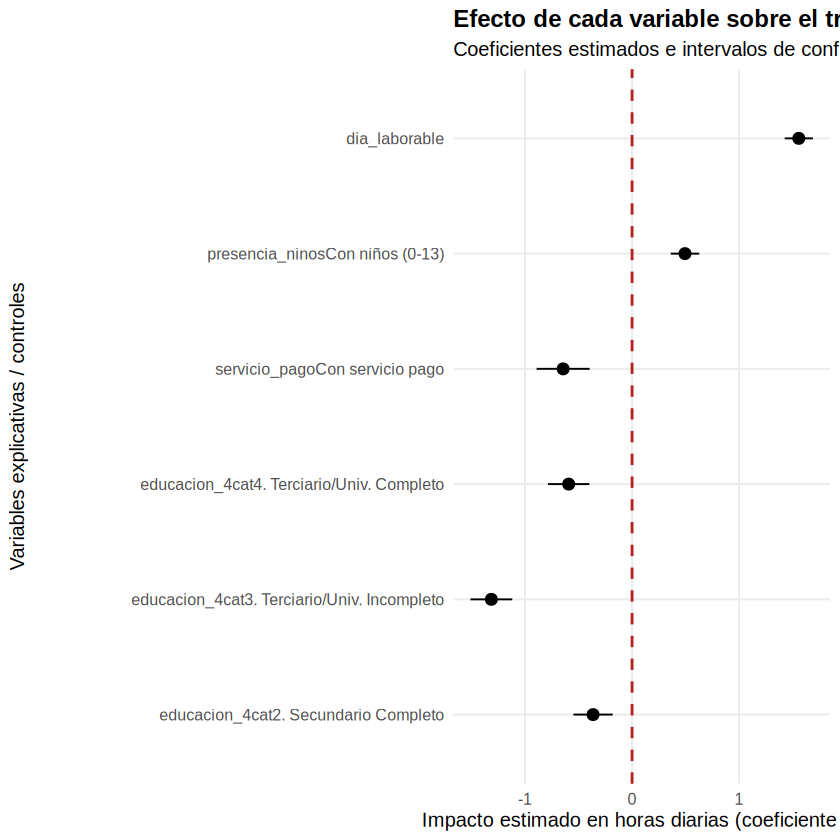

In [ ]:
# 6. Gráfico de Coeficientes del Modelo (modelplot + ggplot2)
modelplot(modelo_reg, vcov = "HC1", coef_omit = "Intercept") +
  geom_vline(xintercept = 0, linetype = "dashed", color = "firebrick", linewidth = 0.8) +
  labs(
    title = "Efecto de cada variable sobre el trabajo doméstico no remunerado",
    subtitle = "Coeficientes estimados e intervalos de confianza del 95% (Errores robustos HC1)",
    x = "Impacto estimado en horas diarias (coeficiente β)",
    y = "Variables explicativas / controles"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    plot.title = element_text(face = "bold"),
    panel.grid.minor = element_blank()
  )
ggsave("output/graficos/modelplot_coeficientes.png", width = 8, height = 5, dpi = 300)

In [ ]:
system("zip -r entrega_graficos_tp2.zip output")

In [4]:
#Análisis de Componentes Principales (PCA)
#Objetivo: resumir 4 variables de uso del tiempo en pocos ejes para ver cómo se organiza el trabajo no remunerado de las mujeres.

# cargado de base de datos
# sep = "|" porque los datos están separados por barras
datos <- read.delim("enut2021_base.txt", sep = "|", header = TRUE, dec = ".")

# Dimensiones iniciales de toda la base
#Muestra cuántas filas y columnas tiene la base completa (14.350 personas y 327 variables).
print("Dimensiones totales de la base:")
print(dim(datos))

# Filtro de la muestra del estudio:
# Mujeres (SEXO_SEL == 1) con edad entre 18 y 64 años (EDAD_SEL)
datos_muestra <- subset(datos, SEXO_SEL == 1 & EDAD_SEL >= 18 & EDAD_SEL <= 64)

# Tamaño de muestra depurada (debe rondar los 6.077 casos)
# Chequea cuántas mujeres quedaron con ese primer filtro (6.077)
print("Tamaño de la muestra filtrada (Mujeres 18-64 años):")
print(nrow(datos_muestra))

# Valores faltantes (exclusión de Ns/nc y educación especial)
# Repite el filtro y además saca los casos con "no sabe/no contesta" y educación especial (códigos 8, 9, 99).
# También saca los "no sabe" en servicio doméstico pago.
datos_muestra <- subset(
  datos,
  SEXO_SEL == 1 &
  EDAD_SEL >= 18 &
  EDAD_SEL <= 64 &
  !(NIVEL_EDUCATIVO_SEL %in% c(8, 9, 99)) &
  !(T_DOMESTICO_PAGO %in% c(9, 99))
)

# Tamaño final de la muestra depurada
print(paste("Tamaño de la muestra final depurada:", nrow(datos_muestra)))

# Carga el paquete tidyverse, que trae las funciones select(), mutate(), group_by(), etc.
library(tidyverse)

# SELECCIÓN DE VARIABLES PARA EL PCA
# Se queda con las 4 variables numéricas. No incluimos WPER porque es el ponderador de la encuesta y no mide nada de las mujeres.
# drop_na() borra filas con datos faltantes (en este caso no borra ninguna).
base_pca <- datos_muestra %>%
  select(
    EDAD_SEL,             # Edad en años cumplidos (discreta)
    TCS_GRUPO_DOMESTICO,  # Minutos diarios en trabajo doméstico no pago - HS_DOMESTICO (continua)
    TCS_GRUPO_CUIDADO,    # Minutos diarios en cuidado directo - HS_CUIDADO (continua)
    CANT_PERSONASHASTA13, # Cantidad de niños de 0 a 13 años en el hogar (discreta)
  ) %>%
  drop_na()

# PCA
# Corre el PCA. center = TRUE resta la media y scale. = TRUE estandariza las variables,
# para que los minutos no pesen más que los años o los niños solo por tener números más grandes.
# (Recordar que scale = TRUE es clave para que todas tengan la misma varianza)
pca_resultado <- prcomp(base_pca, center = TRUE, scale. = TRUE)

# VeMOS el resumen de cuánta varianza explica cada componente
summary(pca_resultado)

# Gráfico de sedimentación (Scree plot) para ver los autovalores
# Dibuja los autovalores de cada componente. Sirve para ver dónde está el "codo", o sea,
# dónde la curva deja de caer fuerte, y decidir cuántos componentes quedarnos.
screeplot(pca_resultado, type = "lines", main = "Scree Plot")

# Ver las cargas (los loadings) para interpretar los ejes
# Muestra cuánto pesa cada variable en cada componente. Sirve para ponerle nombre a los ejes.
pca_resultado$rotation

# Biplot básico para ver las relaciones
# Grafica juntas a las mujeres (puntos) y a las variables (flechas) en PC1 y PC2.
# xlabs = "." reemplaza el número de cada mujer por un punto, para que se pueda leer.
biplot(pca_resultado, xlabs = rep(".", nrow(base_pca)))

# Guardar las dos primeras componentes en la base de datos para seguir analizando
# Guarda en la base el puntaje de cada mujer en PC1 y PC2, para poder compararlos por grupos después.
datos_muestra$PC1 <- pca_resultado$x[, 1]
datos_muestra$PC2 <- pca_resultado$x[, 2]

pca_resultado$rotation

# Puntajes por nivel educativo y por servicio doméstico pago
# Crea dos variables nuevas: el nivel educativo en 4 categorías y si el hogar tiene servicio doméstico pago.
datos_muestra <- datos_muestra %>%
  mutate(
    educacion = case_when(
      NIVEL_EDUCATIVO_SEL %in% 1:4 ~ "1. Hasta sec. incompleto",
      NIVEL_EDUCATIVO_SEL == 5     ~ "2. Secundario completo",
      NIVEL_EDUCATIVO_SEL == 6     ~ "3. Terciario/univ. incompleto",
      NIVEL_EDUCATIVO_SEL == 7     ~ "4. Terciario/univ. completo"),
    servicio = if_else(T_DOMESTICO_PAGO == 1, "Con servicio", "Sin servicio")
  )

# Calcula el puntaje promedio en PC1 y PC2 para cada nivel educativo.
datos_muestra %>% group_by(educacion) %>%
  summarise(n = n(), PC1 = round(mean(PC1), 2), PC2 = round(mean(PC2), 2))

# Lo mismo, pero según si el hogar tiene servicio doméstico pago o no.
datos_muestra %>% group_by(servicio) %>%
  summarise(n = n(), PC1 = round(mean(PC1), 2), PC2 = round(mean(PC2), 2))

# Robustez: PCA sin los 73 outliers (más de 660 min = 11 hs de trabajo doméstico)
# Saca a las 73 mujeres con más de 660 minutos (11 hs) de trabajo doméstico y repite el PCA.
# Sirve para ver si esos casos extremos cambian los resultados.
base_sin_out <- base_pca %>% filter(TCS_GRUPO_DOMESTICO <= 660)
nrow(base_sin_out)   # debe dar 5969
pca_sin_out <- prcomp(base_sin_out, center = TRUE, scale. = TRUE)
summary(pca_sin_out)
round(pca_sin_out$rotation, 2)

# Correlaciones entre las variables (el PCA resume variables relacionadas)
# El PCA sirve cuando las variables se relacionan, porque ahí hay algo que resumir.
round(cor(base_pca), 2)

# Autovalores (criterio de Kaiser: mayor a 1)
# Muestra el autovalor de cada componente. Criterio de Kaiser: nos quedamos con los que superan 1.
round(pca_resultado$sdev^2, 2)

# Sensibilidad: repetir el PCA sacando una variable por vez
# Repite el PCA sacando una variable por vez y muestra el % de varianza de PC1 y PC2.
# Sirve para ver cuánto depende el resultado de cada variable.
for (v in names(base_pca)) {
  pca_prueba <- prcomp(base_pca[, names(base_pca) != v], center = TRUE, scale. = TRUE)
  print(paste("Sin", v))
  print(summary(pca_prueba)$importance[2:3, 1:2])   # % de varianza y acumulado de PC1 y PC2
}


Warning message in file(file, "rt"):
“cannot open file 'enut2021_base.txt': No such file or directory”


ERROR: Error in file(file, "rt"): cannot open the connection


[1] "Dimensiones totales de la base:"
[1] 14350   327
[1] "Tamaño de la muestra filtrada (Mujeres 18-64 años):"
[1] 6077
[1] "Tamaño de la muestra final depurada: 6042"


Importance of components:
                          PC1    PC2    PC3    PC4
Standard deviation     1.3137 1.0987 0.7885 0.6673
Proportion of Variance 0.4314 0.3018 0.1555 0.1113
Cumulative Proportion  0.4314 0.7332 0.8887 1.0000

,PC1,PC2,PC3,PC4
EDAD_SEL,0.3591739,-0.63990868,0.6627876,0.14907596
TCS_GRUPO_DOMESTICO,-0.1920328,-0.75962440,-0.6199664,-0.04166394
TCS_GRUPO_CUIDADO,-0.6365593,-0.11496283,0.3823750,-0.65982204
CANT_PERSONASHASTA13,-0.6549120,-0.01646791,0.1736195,0.73530630


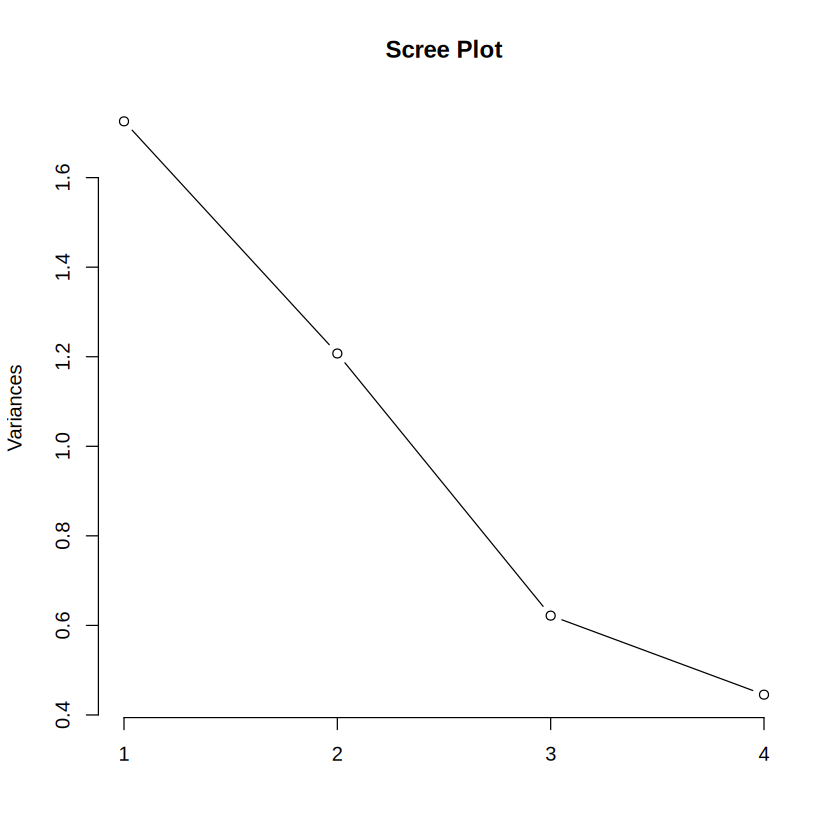

,PC1,PC2,PC3,PC4
EDAD_SEL,0.3591739,-0.63990868,0.6627876,0.14907596
TCS_GRUPO_DOMESTICO,-0.1920328,-0.75962440,-0.6199664,-0.04166394
TCS_GRUPO_CUIDADO,-0.6365593,-0.11496283,0.3823750,-0.65982204
CANT_PERSONASHASTA13,-0.6549120,-0.01646791,0.1736195,0.73530630


educacion,n,PC1,PC2
<chr>,<int>,<dbl>,<dbl>
1. Hasta sec. incompleto,1661,-0.13,-0.37
2. Secundario completo,1678,-0.14,-0.05
3. Terciario/univ. incompleto,1192,0.05,0.63
4. Terciario/univ. completo,1511,0.27,-0.03


servicio,n,PC1,PC2
<chr>,<int>,<dbl>,<dbl>
Con servicio,345,0.26,0.12
Sin servicio,5697,-0.02,-0.01


[1] 5969

Importance of components:
                          PC1    PC2    PC3    PC4
Standard deviation     1.3151 1.0970 0.7891 0.6666
Proportion of Variance 0.4324 0.3009 0.1557 0.1111
Cumulative Proportion  0.4324 0.7333 0.8889 1.0000

,PC1,PC2,PC3,PC4
EDAD_SEL,0.35,-0.65,0.66,0.14
TCS_GRUPO_DOMESTICO,-0.21,-0.75,-0.62,-0.04
TCS_GRUPO_CUIDADO,-0.64,-0.10,0.38,-0.66
CANT_PERSONASHASTA13,-0.65,-0.01,0.18,0.73


,EDAD_SEL,TCS_GRUPO_DOMESTICO,TCS_GRUPO_CUIDADO,CANT_PERSONASHASTA13
EDAD_SEL,1.00,0.21,-0.19,-0.27
TCS_GRUPO_DOMESTICO,0.21,1.00,0.18,0.15
TCS_GRUPO_CUIDADO,-0.19,0.18,1.00,0.55
CANT_PERSONASHASTA13,-0.27,0.15,0.55,1.00


[1] 1.73 1.21 0.62 0.45

[1] "Sin EDAD_SEL"
                           PC1     PC2
Proportion of Variance 0.54477 0.30451
Cumulative Proportion  0.54477 0.84928
[1] "Sin TCS_GRUPO_DOMESTICO"
                           PC1     PC2
Proportion of Variance 0.56717 0.28420
Cumulative Proportion  0.56717 0.85137
[1] "Sin TCS_GRUPO_CUIDADO"
                           PC1     PC2
Proportion of Variance 0.42766 0.38119
Cumulative Proportion  0.42766 0.80885
[1] "Sin CANT_PERSONASHASTA13"
                          PC1     PC2
Proportion of Variance 0.4036 0.39263
Cumulative Proportion  0.4036 0.79624


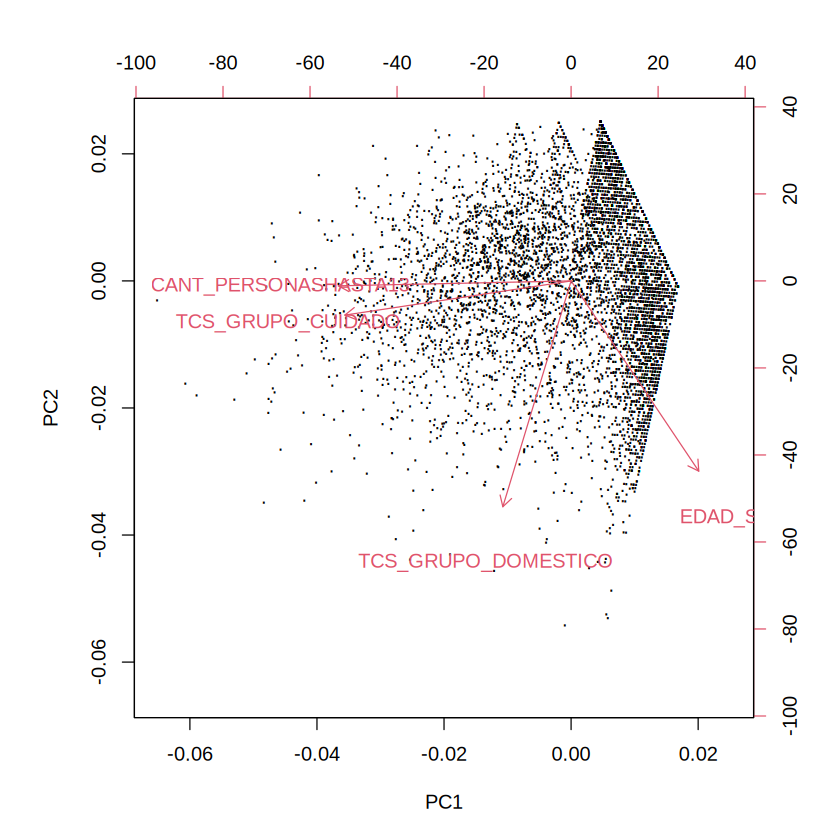

In [8]:
#Análisis de Componentes Principales (PCA)
#Objetivo: resumir 4 variables de uso del tiempo en pocos ejes para ver cómo se organiza el trabajo no remunerado de las mujeres.

# cargado de base de datos
# sep = "|" porque los datos están separados por barras
datos <- read.delim("enut2021_base.txt", sep = "|", header = TRUE, dec = ".")

# Dimensiones iniciales de toda la base
#Muestra cuántas filas y columnas tiene la base completa (14.350 personas y 327 variables).
print("Dimensiones totales de la base:")
print(dim(datos))

# Filtro de la muestra del estudio:
# Mujeres (SEXO_SEL == 1) con edad entre 18 y 64 años (EDAD_SEL)
datos_muestra <- subset(datos, SEXO_SEL == 1 & EDAD_SEL >= 18 & EDAD_SEL <= 64)

# Tamaño de muestra depurada (debe rondar los 6.077 casos)
# Chequea cuántas mujeres quedaron con ese primer filtro (6.077)
print("Tamaño de la muestra filtrada (Mujeres 18-64 años):")
print(nrow(datos_muestra))

# Valores faltantes (exclusión de Ns/nc y educación especial)
# Repite el filtro y además saca los casos con "no sabe/no contesta" y educación especial (códigos 8, 9, 99).
# También saca los "no sabe" en servicio doméstico pago.
datos_muestra <- subset(
  datos,
  SEXO_SEL == 1 &
  EDAD_SEL >= 18 &
  EDAD_SEL <= 64 &
  !(NIVEL_EDUCATIVO_SEL %in% c(8, 9, 99)) &
  !(T_DOMESTICO_PAGO %in% c(9, 99))
)

# Tamaño final de la muestra depurada
print(paste("Tamaño de la muestra final depurada:", nrow(datos_muestra)))

# Carga el paquete tidyverse, que trae las funciones select(), mutate(), group_by(), etc.
library(tidyverse)

# SELECCIÓN DE VARIABLES PARA EL PCA
# Se queda con las 4 variables numéricas. No incluimos WPER porque es el ponderador de la encuesta y no mide nada de las mujeres.
# drop_na() borra filas con datos faltantes (en este caso no borra ninguna).
base_pca <- datos_muestra %>%
  select(
    EDAD_SEL,             # Edad en años cumplidos (discreta)
    TCS_GRUPO_DOMESTICO,  # Minutos diarios en trabajo doméstico no pago - HS_DOMESTICO (continua)
    TCS_GRUPO_CUIDADO,    # Minutos diarios en cuidado directo - HS_CUIDADO (continua)
    CANT_PERSONASHASTA13, # Cantidad de niños de 0 a 13 años en el hogar (discreta)
  ) %>%
  drop_na()

# PCA
# Corre el PCA. center = TRUE resta la media y scale. = TRUE estandariza las variables,
# para que los minutos no pesen más que los años o los niños solo por tener números más grandes.
# (Recordar que scale = TRUE es clave para que todas tengan la misma varianza)
pca_resultado <- prcomp(base_pca, center = TRUE, scale. = TRUE)

# VeMOS el resumen de cuánta varianza explica cada componente
summary(pca_resultado)

# Gráfico de sedimentación (Scree plot) para ver los autovalores
# Dibuja los autovalores de cada componente. Sirve para ver dónde está el "codo", o sea,
# dónde la curva deja de caer fuerte, y decidir cuántos componentes quedarnos.
screeplot(pca_resultado, type = "lines", main = "Scree Plot")

# Ver las cargas (los loadings) para interpretar los ejes
# Muestra cuánto pesa cada variable en cada componente. Sirve para ponerle nombre a los ejes.
pca_resultado$rotation

# Biplot básico para ver las relaciones
# Grafica juntas a las mujeres (puntos) y a las variables (flechas) en PC1 y PC2.
# xlabs = "." reemplaza el número de cada mujer por un punto, para que se pueda leer.
biplot(pca_resultado, xlabs = rep(".", nrow(base_pca)))

# Guardar las dos primeras componentes en la base de datos para seguir analizando
# Guarda en la base el puntaje de cada mujer en PC1 y PC2, para poder compararlos por grupos después.
datos_muestra$PC1 <- pca_resultado$x[, 1]
datos_muestra$PC2 <- pca_resultado$x[, 2]

pca_resultado$rotation

# Puntajes por nivel educativo y por servicio doméstico pago
# Crea dos variables nuevas: el nivel educativo en 4 categorías y si el hogar tiene servicio doméstico pago.
datos_muestra <- datos_muestra %>%
  mutate(
    educacion = case_when(
      NIVEL_EDUCATIVO_SEL %in% 1:4 ~ "1. Hasta sec. incompleto",
      NIVEL_EDUCATIVO_SEL == 5     ~ "2. Secundario completo",
      NIVEL_EDUCATIVO_SEL == 6     ~ "3. Terciario/univ. incompleto",
      NIVEL_EDUCATIVO_SEL == 7     ~ "4. Terciario/univ. completo"),
    servicio = if_else(T_DOMESTICO_PAGO == 1, "Con servicio", "Sin servicio")
  )

# Calcula el puntaje promedio en PC1 y PC2 para cada nivel educativo.
datos_muestra %>% group_by(educacion) %>%
  summarise(n = n(), PC1 = round(mean(PC1), 2), PC2 = round(mean(PC2), 2))

# Lo mismo, pero según si el hogar tiene servicio doméstico pago o no.
datos_muestra %>% group_by(servicio) %>%
  summarise(n = n(), PC1 = round(mean(PC1), 2), PC2 = round(mean(PC2), 2))

# Robustez: PCA sin los 73 outliers (más de 660 min = 11 hs de trabajo doméstico)
# Saca a las 73 mujeres con más de 660 minutos (11 hs) de trabajo doméstico y repite el PCA.
# Sirve para ver si esos casos extremos cambian los resultados.
base_sin_out <- base_pca %>% filter(TCS_GRUPO_DOMESTICO <= 660)
nrow(base_sin_out)   # debe dar 5969
pca_sin_out <- prcomp(base_sin_out, center = TRUE, scale. = TRUE)
summary(pca_sin_out)
round(pca_sin_out$rotation, 2)

# Correlaciones entre las variables (el PCA resume variables relacionadas)
# El PCA sirve cuando las variables se relacionan, porque ahí hay algo que resumir.
round(cor(base_pca), 2)

# Autovalores (criterio de Kaiser: mayor a 1)
# Muestra el autovalor de cada componente. Criterio de Kaiser: nos quedamos con los que superan 1.
round(pca_resultado$sdev^2, 2)

# Sensibilidad: repetir el PCA sacando una variable por vez
# Repite el PCA sacando una variable por vez y muestra el % de varianza de PC1 y PC2.
# Sirve para ver cuánto depende el resultado de cada variable.
for (v in names(base_pca)) {
  pca_prueba <- prcomp(base_pca[, names(base_pca) != v], center = TRUE, scale. = TRUE)
  print(paste("Sin", v))
  print(summary(pca_prueba)$importance[2:3, 1:2])   # % de varianza y acumulado de PC1 y PC2
}
